# From CNN filters to Fourier multipliers

[![Open in Colab](https://img.shields.io/badge/Open%20in-Colab-F9AB00?style=flat-square&logo=googlecolab)](https://colab.research.google.com/github/kks32-courses/sciml/blob/main/docs/05-fno/fno-cnn-comparisons.ipynb)

A CNN filter slides across an image, taking a weighted sum of nearby pixels at every position. A Fourier layer appears to do something entirely different: it transforms a field into waves and multiplies each wave's coefficient by a learned weight.

**How can a sliding sum and a multiplication describe the same operation?** That question is the thread running through this notebook.

We'll begin with the CNN animations from the Module 6 slides, then ask a filter to process just **one wave**. Something remarkable happens: the output has the same frequency as the input. The filter can change the wave's height or shift it sideways, but it does not change the number of oscillations. Once we understand that, convolution in Fourier space becomes multiplication almost automatically.

Finally, we'll use heat flow on a ring to compare two ways of *learning* a spatial operator: fitting the weights of a local CNN filter and fitting the multipliers of a Fourier layer. We'll also test what happens when we change the grid resolution.

This notebook isolates the **linear convolution part** of an FNO so that its basic idea is visible. A full FNO also has multiple feature channels, pointwise transformations, and nonlinear activations; see [fno.ipynb](fno.ipynb). For the heat equation derivation, see [the heat-flow lesson](fno-intuition.ipynb). Run the cells in order; only NumPy and Matplotlib are needed.


In [1]:
from pathlib import Path
import base64
import tempfile
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import HTML, Markdown, display

FIELD, EXACT, LEARNED, INK = '#008577', '#7251a1', '#db6a20', '#253349'
plt.rcParams.update({
    'figure.dpi': 100, 'font.size': 11, 'axes.spines.top': False,
    'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': 0.18,
    'axes.prop_cycle': plt.cycler(color=[FIELD, LEARNED, EXACT]),
})
FIGS_URL = 'https://raw.githubusercontent.com/kks32-courses/sciml/main/docs/05-fno/figs/'

def deck_gif(name, alt, width):
    # An <img> tag for a GIF from the CNN deck, read from figs/ or from the course repository.
    for folder in [Path('figs'), Path('docs/05-fno/figs')]:
        if (folder / name).is_file():
            data = base64.b64encode((folder / name).read_bytes()).decode('ascii')
            return f'<img alt="{alt}" width="{width}" src="data:image/gif;base64,{data}">'
    return f'<img alt="{alt}" width="{width}" src="{FIGS_URL}{name}">'

def show_animation(fig, update, frames, fps):
    # Render a Matplotlib animation to a GIF and show it inline.
    animation = FuncAnimation(fig, update, frames=frames)
    with tempfile.TemporaryDirectory() as folder:
        path = Path(folder) / 'animation.gif'
        animation.save(path, writer=PillowWriter(fps=fps), dpi=72)
        data = base64.b64encode(path.read_bytes()).decode('ascii')
    plt.close(fig)
    display(HTML(f'<img style="max-width:100%" src="data:image/gif;base64,{data}">'))

def grid(n):
    return np.linspace(0, 2*np.pi, n, endpoint=False)

def rfft(u):
    return np.fft.rfft(u, axis=-1, norm='forward')

def irfft(a, n):
    return np.fft.irfft(a, n=n, axis=-1, norm='forward')

def offsets_of(weights):
    # A filter with 2m+1 weights uses the offsets -m, ..., m.
    m = len(weights) // 2
    return np.arange(-m, m + 1)

def convolve(u, weights):
    # y_j = sum_r w_r u_{j-r}, with indices wrapping around the ring.
    return sum(w*np.roll(u, int(r), axis=-1) for r, w in zip(offsets_of(weights), weights))

def convolve2d(image, kernel):
    # The CNN sum out[i, j] = sum_ab K[a, b] image[i+a-1, j+b-1], wrapping at the edges.
    return sum(kernel[a, b]*np.roll(image, (1 - a, 1 - b), axis=(0, 1))
               for a in range(3) for b in range(3))

def response(weights, k, n):
    # R(k) = sum_r w_r exp(-i theta_k r) with theta_k = 2 pi k / n.
    r = offsets_of(weights)[:, None]
    return (np.asarray(weights)[:, None]*np.exp(-2j*np.pi*r*np.asarray(k)/n)).sum(axis=0)

def fit_filter(inputs, targets, width):
    # Least-squares weights of a linear convolution layer with `width` weights.
    m = width // 2
    columns = np.stack([np.roll(inputs, r, axis=-1).ravel() for r in range(-m, m + 1)], axis=1)
    return np.linalg.lstsq(columns, targets.ravel(), rcond=None)[0]

def mean_relative_error(prediction, target):
    return np.mean(np.linalg.norm(prediction - target, axis=-1) / np.linalg.norm(target, axis=-1))

def close_periodic(xx, values):
    return np.r_[xx, 2*np.pi], np.r_[values, values[0]]

## 1. What does a CNN filter actually do?

Start with the animation from slide 14. The $3\times3$ filter is

$$
K=\begin{bmatrix}
1&0&1\\
0&1&0\\
1&0&1
\end{bmatrix}.
$$

Place it over the upper-left $3\times3$ patch of a $5\times5$ image. Multiply each pixel by the weight directly above it, then add the nine products. **That one sum gives one output pixel.** Move the filter to the next location and repeat.

Notice that we reuse *exactly the same nine weights* wherever the filter goes. This shared rule—not a separate set of weights for each pixel—is what makes it a convolution-like operation.



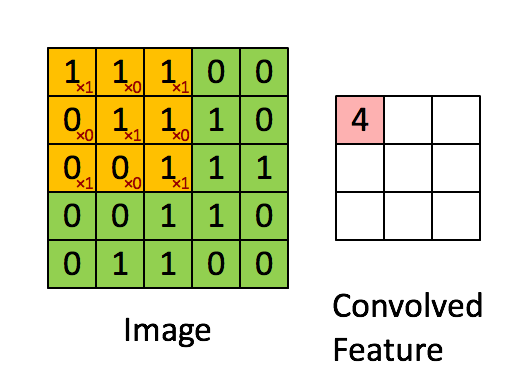

In [2]:
display(HTML(deck_gif('cnn-kernel.gif', 'A 3 by 3 filter sliding over a 5 by 5 image, slide 14', 526)))

Before looking at the computation, check the first output by hand. Only the four corners and center of the filter have nonzero weights. In the first image patch, those five pixel values are $1,1,1,0,1$, so

$$1+1+1+0+1=4.$$

The next cell repeats the same multiply-and-add operation at all nine valid filter positions. Compare its output with the final frame of the animation.


In [3]:
slide14_image = np.array([[1, 1, 1, 0, 0],
                          [0, 1, 1, 1, 0],
                          [0, 0, 1, 1, 1],
                          [0, 0, 1, 1, 0],
                          [0, 1, 1, 0, 0]])
slide14_filter = np.array([[1, 0, 1],
                           [0, 1, 0],
                           [1, 0, 1]])
feature = np.array([[np.sum(slide14_image[i:i+3, j:j+3]*slide14_filter) for j in range(3)]
                    for i in range(3)])
print(feature)

[[4 3 4]
 [2 4 3]
 [2 3 4]]


The $3\times3$ output agrees with the animation. It is smaller than the $5\times5$ input because the filter is placed only where its entire $3\times3$ window fits; we have not added padding.

Two choices change how a CNN samples an image:

- **Stride** sets how far the filter jumps between positions. Slide 23 compares stride 1 and stride 2. A larger stride visits fewer positions for a given input size.
- **Padding** extends the image before filtering. The zero padding in slide 27 can preserve the input's spatial dimensions.

The animations below show the different strides. The two examples use different input sizes, but both produce a $2\times2$ output.



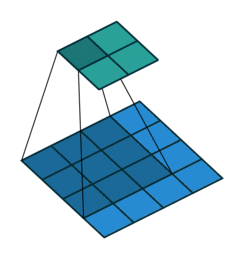
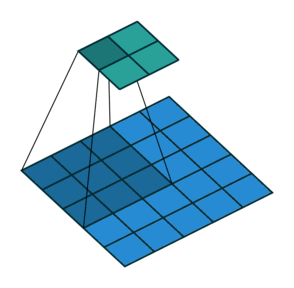

In [4]:
display(HTML('<div style="display:flex; gap:40px; align-items:flex-end">'
             + deck_gif('cnn-stride-1.gif', 'Stride 1 on a 4 by 4 input, slide 23', 244)
             + deck_gif('cnn-stride-2.gif', 'Stride 2 on a 5 by 5 input, slide 23', 294)
             + '</div>'))

Slide 20 adds **max pooling** after convolution: from each small block, keep its largest value. This makes the downstream representation less sensitive to small changes in where a feature appears. Watch the digit 3 move: the pooled features change less than the original pixel pattern, and the classifier keeps recognizing the digit.

That can be useful for image recognition. But for predicting a physical field, we often want something different: if the input moves, the *entire output field* should move by the same amount, not become insensitive to the move.



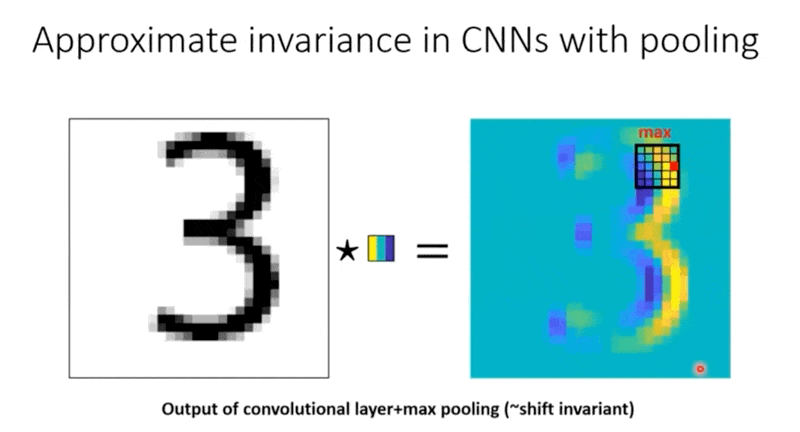

In [5]:
display(HTML(deck_gif('cnn-pooling-shift.gif', 'Max pooling after a convolution as the digit 3 moves, slide 20', 640)))

Imagine temperature measured around a perfectly uniform metal ring. If we rotate the initial temperature pattern five grid points clockwise, the temperature pattern at a later time must also rotate five points clockwise. The physics has no preferred location on the ring.

This property is called **translation equivariance**: shifting the input and then applying the operator gives the same answer as applying the operator and then shifting its output.

A stride-1 convolution with **wraparound (periodic) boundaries** has this property. Strided convolution and downsampling by pooling generally lose exact equivariance to a one-pixel shift: they do not retain every location in the output.

For the rest of the notebook, a *CNN layer* means one stride-1 convolution with no pooling. Our one-dimensional signals live on a ring, so the left neighbor of the first grid point is the last point. The next cell checks that convolution and shifting commute.


In [6]:
ring = np.random.default_rng(0).normal(size=32)
weights = np.array([0.2, 0.5, 0.3])
assert np.allclose(convolve(np.roll(ring, 5), weights), np.roll(convolve(ring, weights), 5))

Now try three familiar filters from slide 15 on a picture:

- **Blur:** all nine weights are $1/9$. Each pixel is replaced by the average of itself and its eight neighbors.
- **Shift:** the output copies the pixel immediately to its left, moving the image one pixel to the right.
- **Sharpen:** the center has weight $5$, and the four nearest neighbors have weight $-1$. This emphasizes changes between neighboring pixels.

The test image contains a broad bright disk, a gray square, and narrow vertical stripes that repeat every three pixels.

**Predict before running:** Which filter will erase the stripes? Which one will exaggerate them? Can you explain why it treats the stripes differently from the large disk?


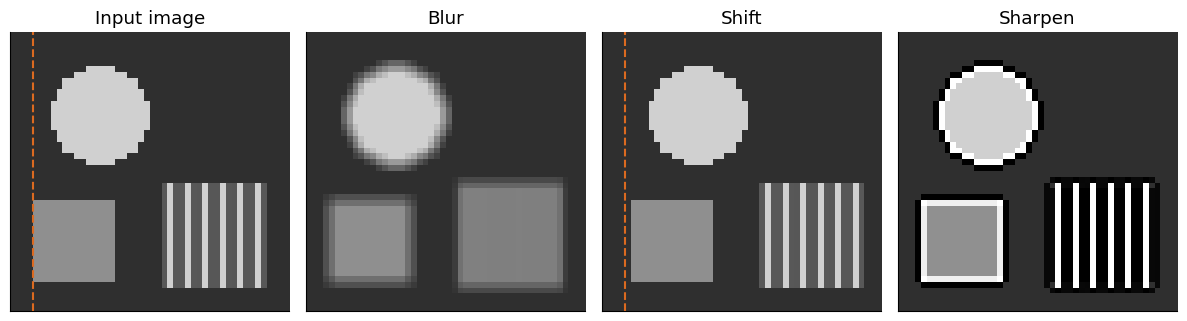

In [7]:
kernels = {
    'Blur': np.full((3, 3), 1/9),
    'Shift': np.array([[0, 0, 0], [1, 0, 0], [0, 0, 0]]),
    'Sharpen': np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]]),
}
M = 48
rows, cols = np.mgrid[0:M, 0:M]
picture = np.zeros((M, M))
picture[(rows - 14)**2 + (cols - 15)**2 <= 8.5**2] = 1.0
picture[29:43, 4:18] = 0.6
stripes = (rows >= 26) & (rows < 44) & (cols >= 26) & (cols < 44)
picture[stripes] = 0.5 + 0.5*np.cos(2*np.pi*cols[stripes]/3)

fig, axes = plt.subplots(1, 4, figsize=(12, 3.3))
panels = {'Input image': picture} | {name: convolve2d(picture, K) for name, K in kernels.items()}
for ax, (name, image) in zip(axes, panels.items()):
    ax.imshow(image, cmap='gray', vmin=-0.3, vmax=1.3, interpolation='nearest')
    ax.set_title(name)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)
for ax in axes[[0, 2]]:
    ax.axvline(3.5, color=LEARNED, lw=1.5, ls='--')
fig.tight_layout()
plt.show()

The blur softens the disk and square, while the stripes become nearly uniform in their interior. The sharpening filter accentuates edges and makes the stripe contrast stronger. The shift moves the whole picture one pixel right. The dashed line marks the square's original left edge; after the shift, a one-pixel gap appears.

But why does the blur suppress fine stripes while preserving most of the broad disk? Saying that it "averages neighboring pixels" describes the calculation, not yet **why different spatial scales respond differently**. To see that, let's reduce the image to one row.


## 2. Reduce the picture to a row of pixels

Suppose every row of the image is identical. Then a $3\times3$ filter can be reduced to a rule involving just three neighboring values in one row, $u_j$.

For our three filters, those rules are

$$
\begin{aligned}
\text{Blur:}\quad &y_j=\tfrac13(u_{j-1}+u_j+u_{j+1}),\\
\text{Shift:}\quad &y_j=u_{j-1},\\
\text{Sharpen:}\quad &y_j=-u_{j-1}+3u_j-u_{j+1}.
\end{aligned}
$$

All three have the same general form:

$$
\boxed{y_j=\sum_{r=-1}^{1}w_r\,u_{j-r}.}
$$

Read this as: **take shifted copies of the input, multiply each by a weight, and add them.** Because the row forms a ring, indices wrap around. For the shift filter, $w_1=1$ and the other weights are zero. The $w_r$ indexing is reversed relative to the order in which the original CNN array stores the columns; the code handles this convention explicitly.

We'll feed the filters a row containing three waves:

$$u(x)=\sin x+\tfrac12\sin3x+\tfrac14\sin7x,$$

sampled at 32 equally spaced points around the ring. The animation shows each filter moving along the row, one point at a time.

**Before running:** Which output keeps the broad wave but loses the fine wiggles? Which amplifies the wiggles? Which shifts the entire shape?



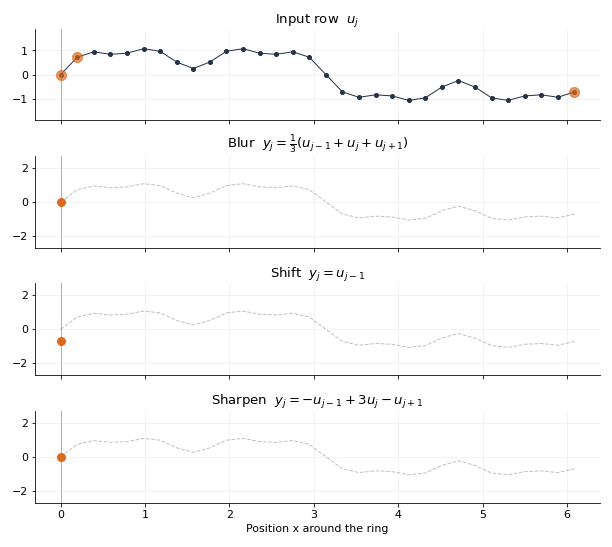

In [8]:
# Column sums are the weights on (u_{j-1}, u_j, u_{j+1}). Reversed, they are (w_{-1}, w_0, w_1).
filters = {name: K.sum(axis=0)[::-1] for name, K in kernels.items()}
N_VIEW = 32
x_view = grid(N_VIEW)
signal = np.sin(x_view) + 0.5*np.sin(3*x_view) + 0.25*np.sin(7*x_view)
for name, K in kernels.items():
    column_image = np.tile(signal, (N_VIEW, 1))
    assert np.allclose(convolve2d(column_image, K)[0], convolve(signal, filters[name]))

outputs = {name: convolve(signal, w) for name, w in filters.items()}
formulas = {
    'Blur': r'Blur  $y_j=\frac{1}{3}(u_{j-1}+u_j+u_{j+1})$',
    'Shift': r'Shift  $y_j=u_{j-1}$',
    'Sharpen': r'Sharpen  $y_j=-u_{j-1}+3u_j-u_{j+1}$',
}
fig, axes = plt.subplots(4, 1, figsize=(8.5, 7.6), sharex=True)
axes[0].plot(x_view, signal, 'o-', color=INK, ms=4, lw=1)
window, = axes[0].plot([], [], 'o', color=LEARNED, ms=10, alpha=0.7)
axes[0].set(title=r'Input row  $u_j$', ylim=(-1.9, 1.9))
cursors = [ax.axvline(0, color=LEARNED, lw=1, alpha=0.6) for ax in axes]
traces, heads = [], []
for ax, (name, out) in zip(axes[1:], outputs.items()):
    ax.plot(x_view, signal, '--', color=INK, alpha=0.3, lw=1)
    trace, = ax.plot([], [], 'o-', color=FIELD, ms=4, lw=1.5)
    head, = ax.plot([], [], 'o', color=LEARNED, ms=8)
    traces.append(trace)
    heads.append(head)
    ax.set(title=formulas[name], ylim=(-2.7, 2.7))
axes[-1].set_xlabel('Position x around the ring')
fig.tight_layout()

def update(frame):
    j = min(frame, N_VIEW - 1)
    under = [(j - 1) % N_VIEW, j, (j + 1) % N_VIEW]
    window.set_data(x_view[under], signal[under])
    for cursor in cursors:
        cursor.set_xdata([x_view[j]])
    for trace, head, out in zip(traces, heads, outputs.values()):
        trace.set_data(x_view[:j + 1], out[:j + 1])
        head.set_data([x_view[j]], [out[j]])

show_animation(fig, update, frames=N_VIEW + 8, fps=4)

The blur reduces the fine wiggles; the sharpening filter makes them stronger; the shift moves the signal one grid point to the right. The slowly varying $\sin x$ component changes relatively little.

We're getting closer to the explanation. Instead of asking what a filter does to an arbitrary, complicated signal, let's ask the simplest possible question:

**What does this filter do to just one sine wave?**


## 3. Give the filter one wave

Take only the fastest wave in our example, $\sin7x$, and apply each filter separately.

Watch for two things: does the output still have **seven oscillations** around the ring? And if so, what *has* changed?


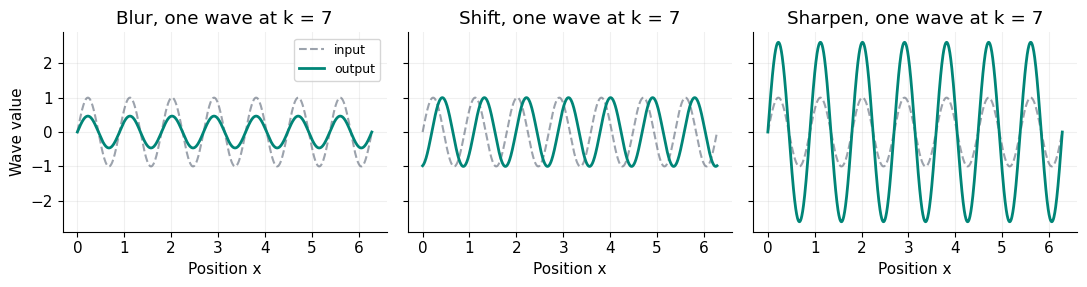

In [9]:
wave_k = 7
h = 2*np.pi/N_VIEW
dense_x = np.linspace(0, 2*np.pi, 1025)
fig, axes = plt.subplots(1, 3, figsize=(11, 3), sharey=True)
for ax, (name, weights) in zip(axes, filters.items()):
    ax.plot(dense_x, np.sin(wave_k*dense_x), '--', color=INK, alpha=0.45, label='input')
    filtered_wave = sum(w*np.sin(wave_k*(dense_x - r*h)) for r, w in zip(offsets_of(weights), weights))
    ax.plot(dense_x, filtered_wave, color=FIELD, lw=2, label='output')
    ax.set(title=f'{name}, one wave at k = {wave_k}', xlabel='Position x', ylim=(-2.9, 2.9))
axes[0].set_ylabel('Wave value')
axes[0].legend(fontsize=9)
fig.tight_layout()
plt.show()

All three outputs still have seven oscillations. Blur and sharpen change the amplitude; shift changes the wave's position, or **phase**. None changes its frequency.

Here's why. Instead of a sine, write a Fourier wave as $e^{ikx}$. On $N$ equally spaced points around a ring, $x_j=jh$ with $h=2\pi/N$. Moving this wave by $r$ grid points gives

$$
\underbrace{e^{ik(x_j-rh)}}_{\text{shifted wave}}
=\underbrace{e^{-ikr h}}_{\text{one complex number}}
\underbrace{e^{ikx_j}}_{\text{original wave}}.
$$

**A shifted Fourier wave is still the same wave, multiplied by a number.** That is the entire trick.

Our convolution adds several shifted copies. Since each copy is the original wave times a number, we can factor out the wave:

$$
\begin{aligned}
y_j
&=\sum_r w_r e^{ik(x_j-rh)}\\
&=\left(\sum_r w_r e^{-i\theta_k r}\right)e^{ikx_j}
=R(k)e^{ikx_j},
\qquad \theta_k=\frac{2\pi k}{N}.
\end{aligned}
$$

Thus each frequency has **one multiplier**,

$$\boxed{R(k)=\sum_r w_r e^{-i\theta_k r}.}$$

$R(k)$ is the filter's *frequency response*. Its magnitude changes the wave's amplitude; its complex angle shifts the wave's phase. For the three filters,

$$
\begin{aligned}
R_{\rm blur}(k)&=\frac{1+2\cos\theta_k}{3},\\
R_{\rm shift}(k)&=e^{-i\theta_k},\\
R_{\rm sharpen}(k)&=3-2\cos\theta_k.
\end{aligned}
$$

For example, with $N=32$ and $k=7$, $\theta_7=14\pi/32\approx1.37$ and $\cos\theta_7\approx0.20$. So blur multiplies this wave by about $0.46$; sharpen multiplies it by about $2.6$.

The next animation feeds modes $k=1$ through $15$ into each filter. The upper plots show input and output waves. The lower plots reveal the **entire frequency response**; an orange dot marks the mode currently being tested. For the shift filter, the lower plot shows phase instead of magnitude.



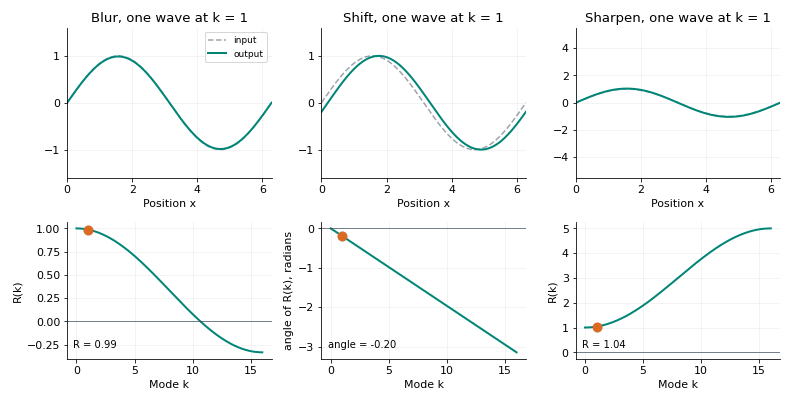

In [10]:
k_waves = np.arange(1, N_VIEW//2)
k_curve = np.linspace(0, N_VIEW/2, 200)
curves = {
    'Blur': response(filters['Blur'], k_curve, N_VIEW).real,
    'Shift': np.angle(response(filters['Shift'], k_curve, N_VIEW)),
    'Sharpen': response(filters['Sharpen'], k_curve, N_VIEW).real,
}
labels = {'Blur': 'R(k)', 'Shift': 'angle of R(k), radians', 'Sharpen': 'R(k)'}
notes_format = {'Blur': 'R = {:.2f}', 'Shift': 'angle = {:.2f}', 'Sharpen': 'R = {:.2f}'}
wave_limits = {'Blur': 1.6, 'Shift': 1.6, 'Sharpen': 5.5}

fig, axes = plt.subplots(2, 3, figsize=(11, 5.6), gridspec_kw={'height_ratios': [1.1, 1]})
wave_lines, out_lines, dots, notes = [], [], [], []
for col, name in enumerate(filters):
    top, bottom = axes[0, col], axes[1, col]
    wave_line, = top.plot([], [], '--', color=INK, alpha=0.45, label='input')
    out_line, = top.plot([], [], color=FIELD, lw=2, label='output')
    top.set(xlim=(0, 2*np.pi), ylim=(-wave_limits[name], wave_limits[name]), xlabel='Position x',
            title=f'{name}, one wave at k = 1')
    bottom.plot(k_curve, curves[name], color=FIELD, lw=2)
    bottom.axhline(0, color=INK, lw=0.6)
    dot, = bottom.plot([], [], 'o', color=LEARNED, ms=9)
    note = bottom.text(0.03, 0.08, '', transform=bottom.transAxes, fontsize=10)
    bottom.set(xlabel='Mode k', ylabel=labels[name])
    wave_lines.append(wave_line)
    out_lines.append(out_line)
    dots.append(dot)
    notes.append(note)
axes[0, 0].legend(fontsize=9, loc='upper right')
fig.tight_layout()

def update(frame):
    k = k_waves[min(frame, len(k_waves) - 1)]
    for col, (name, weights) in enumerate(filters.items()):
        filtered_wave = sum(w*np.sin(k*(dense_x - r*h)) for r, w in zip(offsets_of(weights), weights))
        wave_lines[col].set_data(dense_x, np.sin(k*dense_x))
        out_lines[col].set_data(dense_x, filtered_wave)
        axes[0, col].set_title(f'{name}, one wave at k = {k}')
        value = response(weights, [k], N_VIEW)[0]
        value = np.angle(value) if name == 'Shift' else value.real
        dots[col].set_data([k], [value])
        notes[col].set_text(notes_format[name].format(value))

show_animation(fig, update, frames=len(k_waves) + 3, fps=1)

Look at the three response curves, not just the waves:

- **Blur:** $R(k)$ decreases with frequency. Above $k=10$ it becomes negative, meaning the wave also flips sign (a phase change of $\pi$).
- **Sharpen:** $R(k)$ increases from $1$ toward $5$, so higher frequencies are amplified.
- **Shift:** $|R(k)|=1$ for every frequency. Its phase is $-\theta_k$: a one-pixel translation corresponds to a larger phase shift for shorter waves.

At $k=0$ all three multipliers equal $1$. A constant input is unchanged by these particular filters.

We've learned how a filter acts on **one** wave. A general row contains many waves at once. What happens when we add them?


## 4. Why convolution becomes multiplication

Any sampled periodic signal can be assembled from Fourier waves:

$$u_j=\sum_k a_k e^{ikx_j}.$$

The Fourier transform (computed with an FFT) finds the coefficients $a_k$: how much of each wave is present. From Section 3 we already know that our filter sends each wave $e^{ikx}$ to $R(k)e^{ikx}$.

Now use **linearity**. A weighted sum of waves passes through a linear filter one wave at a time:

$$
\begin{aligned}
\mathcal Ku
&=\mathcal K\left(\sum_k a_k e^{ikx}\right)\\
&=\sum_k a_k\,\mathcal K(e^{ikx})\\
&=\sum_k \underbrace{R(k)a_k}_{\text{new coefficient}}e^{ikx}.
\end{aligned}
$$

In other words,

$$
\boxed{a_k^{\rm out}=R(k)a_k^{\rm in}},
\qquad
\boxed{u_{\rm out}=\mathcal F^{-1}\!\left[R(k)\,\mathcal F(u_{\rm in})\right]}.
$$

This is the **convolution theorem**. The filter still represents the same spatial interaction. We have simply described it in a different basis: one in which every wave is processed by its own multiplier instead of by a sliding sum.

> A spatial kernel tells us how neighboring **positions** contribute. Its Fourier response tells us how different **wavelengths** are amplified or shifted. These are two descriptions of the *same convolution*.

Follow the animation. The input contains modes 1, 3, and 7. The bars show their amplitudes; faint outlines mark the original amplitudes. Each frame applies $R(k)^t$, moving from the unchanged input ($t=0$) to the full filtered output ($t=1$). The left plots reconstruct the signal from the changing coefficients. Near the end, dots show the output obtained by sliding the filter in physical space.

*Important:* multiplication works this simply because the kernel uses the **same weights everywhere** (translation invariance) and the operation is linear. An arbitrary position-dependent kernel does not, in general, become independent multiplications in Fourier space.



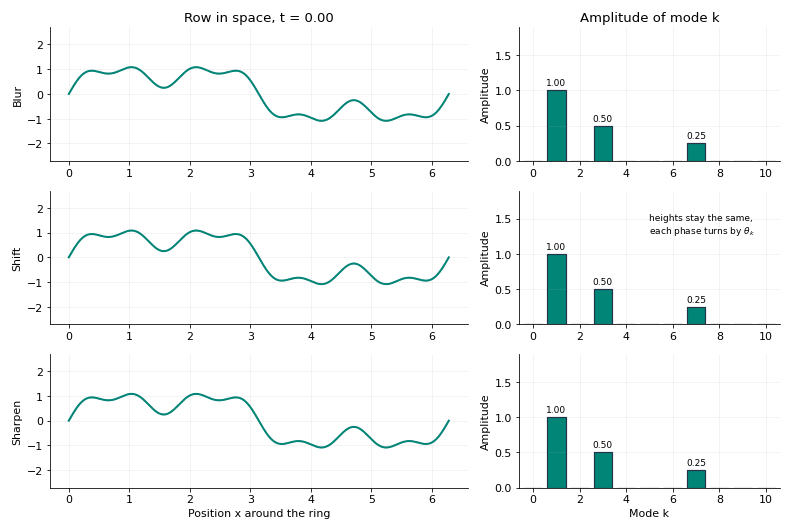

In [11]:
modes = np.arange(N_VIEW//2 + 1)
signal_coefficients = rfft(signal)
input_amplitude = 2*np.abs(signal_coefficients)
steps = np.r_[np.linspace(0, 1, 21), np.ones(12)]

def partial_multiplier(weights, t):
    # R(k)^t: the size of R(k) raised to t, and its angle times t.
    R = response(weights, modes, N_VIEW)
    return np.abs(R)**t*np.exp(1j*t*np.angle(R))

def dense_row(coefficients):
    # The row with these rfft coefficients, evaluated between the grid points.
    k = modes[1:N_VIEW//2]
    return 2*np.real(coefficients[1:N_VIEW//2] @ np.exp(1j*np.outer(k, dense_x)))

for name, weights in filters.items():
    via_fourier = irfft(response(weights, modes, N_VIEW)*signal_coefficients, N_VIEW)
    assert np.allclose(convolve(signal, weights), via_fourier, atol=1e-13)
    assert np.allclose(irfft(partial_multiplier(weights, 1)*signal_coefficients, N_VIEW), via_fourier)

fig, axes = plt.subplots(3, 2, figsize=(11, 7.4), gridspec_kw={'width_ratios': [1.6, 1]})
rows_artists = []
for row, (name, weights) in enumerate(filters.items()):
    left, right = axes[row]
    left.plot(dense_x, dense_row(signal_coefficients), '--', color=INK, alpha=0.4)
    curve, = left.plot([], [], color=FIELD, lw=2)
    sliding, = left.plot([], [], 'o', color=LEARNED, ms=5)
    left.set(ylim=(-2.7, 2.7), ylabel=name)
    bars = right.bar(modes, input_amplitude, width=0.8, color=FIELD)
    right.bar(modes, input_amplitude, width=0.8, fill=False, edgecolor=INK, lw=1.2, zorder=3)
    texts = [right.text(k, 0, '', ha='center', va='bottom', fontsize=9) for k in (1, 3, 7)]
    right.set(ylim=(0, 1.9), xlim=(-0.6, 10.6), ylabel='Amplitude')
    rows_artists.append((curve, sliding, bars, texts))
axes[0, 0].set_title('Row in space')
axes[0, 1].set_title('Amplitude of mode k')
axes[2, 0].set_xlabel('Position x around the ring')
axes[2, 1].set_xlabel('Mode k')
axes[1, 1].text(5.0, 1.3, 'heights stay the same,\neach phase turns by $\\theta_k$', fontsize=9)
fig.tight_layout()

def update(frame):
    t = steps[frame]
    for (curve, sliding, bars, texts), (name, weights) in zip(rows_artists, filters.items()):
        coefficients = partial_multiplier(weights, t)*signal_coefficients
        curve.set_data(dense_x, dense_row(coefficients))
        amplitude = 2*np.abs(coefficients)
        for bar, height in zip(bars, amplitude):
            bar.set_height(height)
        for text, k in zip(texts, (1, 3, 7)):
            text.set_position((k, amplitude[k] + 0.04))
            text.set_text(f'{amplitude[k]:.2f}')
        if frame >= 21:
            sliding.set_data(x_view, outputs[name])
        else:
            sliding.set_data([], [])
    axes[0, 0].set_title(f'Row in space, t = {t:.2f}')

show_animation(fig, update, frames=len(steps), fps=6)

At the final frame, the Fourier-reconstructed curves pass through the dots from the sliding filter. The code also checks equality numerically. **Two different computations, one answer.**

The blur barely changes mode 1 but lowers mode 7 from amplitude $0.25$ to about $0.12$. Sharpen boosts mode 7 by about a factor of $2.6$. Shift keeps every amplitude unchanged and changes only the phases, translating the whole row by one point.

The same logic works for images, except that a two-dimensional wave has a frequency in each direction: $(k_1,k_2)$. A $2$D filter acts on it through a single response $R(k_1,k_2)$.

For the three image filters, with $\theta_{k}=2\pi k/48$,

$$
\begin{aligned}
R_{\rm blur}(k_1,k_2)
&=\frac{(1+2\cos\theta_{k_1})(1+2\cos\theta_{k_2})}{9},\\
R_{\rm shift}(k_1,k_2)&=e^{-i\theta_{k_2}},\\
R_{\rm sharpen}(k_1,k_2)
&=5-2\cos\theta_{k_1}-2\cos\theta_{k_2}.
\end{aligned}
$$

To find these responses numerically, the next cell applies each filter to a *single bright pixel* (an impulse) and takes its $2$D FFT. The resulting maps show which frequencies each filter preserves or suppresses. The center is the constant mode $(0,0)$; orange circles mark the stripe frequencies $(0,\pm16)$.


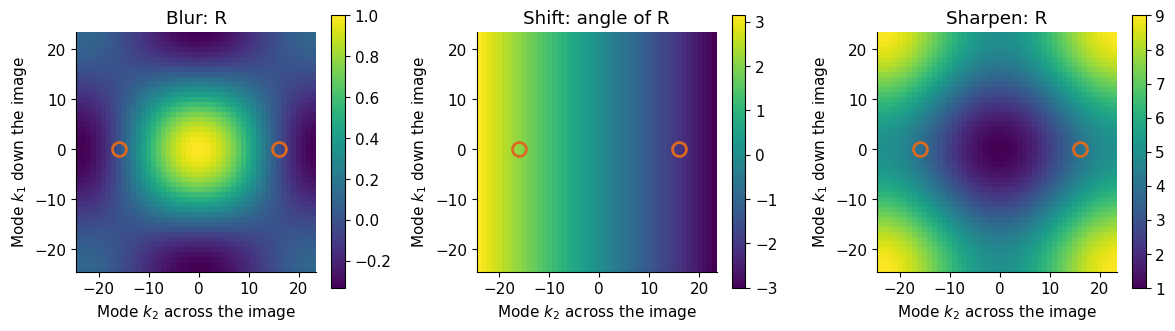

Stripes: blur 0.00, sharpen 4.00


In [12]:
k_axis = np.fft.fftfreq(M, d=1/M)
theta1, theta2 = np.meshgrid(2*np.pi*k_axis/M, 2*np.pi*k_axis/M, indexing='ij')
impulse = np.zeros((M, M))
impulse[0, 0] = 1
responses_2d = {name: np.fft.fft2(convolve2d(impulse, K)) for name, K in kernels.items()}
assert np.allclose(responses_2d['Blur'], (1 + 2*np.cos(theta1))*(1 + 2*np.cos(theta2))/9)
assert np.allclose(responses_2d['Shift'], np.exp(-1j*theta2))
assert np.allclose(responses_2d['Sharpen'], 5 - 2*np.cos(theta1) - 2*np.cos(theta2))
for name, K in kernels.items():
    via_fourier = np.fft.ifft2(responses_2d[name]*np.fft.fft2(picture)).real
    assert np.allclose(convolve2d(picture, K), via_fourier)

shown = {
    'Blur: R': responses_2d['Blur'].real,
    'Shift: angle of R': np.angle(responses_2d['Shift']),
    'Sharpen: R': responses_2d['Sharpen'].real,
}
extent = [-M/2 - 0.5, M/2 - 0.5, -M/2 - 0.5, M/2 - 0.5]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.7))
for ax, (title, values) in zip(axes, shown.items()):
    image = ax.imshow(np.fft.fftshift(values), extent=extent, origin='lower', cmap='viridis')
    ax.plot([-16, 16], [0, 0], 'o', mfc='none', mec=LEARNED, ms=10, mew=2)
    ax.set(title=title, xlabel='Mode $k_2$ across the image', ylabel='Mode $k_1$ down the image')
    ax.grid(False)
    fig.colorbar(image, ax=ax, shrink=0.85)
fig.tight_layout()
plt.show()
print(f"Stripes: blur {responses_2d['Blur'][0, 16].real:.2f}, sharpen {responses_2d['Sharpen'][0, 16].real:.2f}")

Now we can explain the stripes **without sliding the blur filter over even one pixel**.

A stripe repeating every three columns has 16 cycles across a 48-pixel image. Thus $k_2=16$ and $\theta_{k_2}=2\pi/3$, so $\cos\theta_{k_2}=-1/2$. The stripe frequency has no variation in the vertical direction ($k_1=0$).

For the blur,

$$R_{\rm blur}(0,16)=\frac{(1+2)(1-1)}{9}=0.$$

That frequency vanishes. For sharpen,

$$R_{\rm sharpen}(0,16)=5-2+1=4.$$

Its contrast becomes four times as large. Because the stripes occupy only a patch of the image, their boundaries contribute other frequencies too; the zero above explains why the **interior periodic pattern** disappears under blur.

The disk and square contain substantial low-frequency content, which blur mostly retains. Their sharp boundaries also require higher frequencies, which blur weakens and sharpen strengthens. The shift has magnitude one at every mode, changing only phase.

So a CNN filter is **already a Fourier multiplier**. But the few spatial weights constrain the entire response curve. A three-weight filter cannot choose an independent multiplier for each frequency. Is that a problem when we're trying to learn physics?


## 5. A physical test: can a small CNN learn heat flow?

Consider a thin, uniform metal ring. Its temperature $u(x,t)$ evolves according to

$$\frac{\partial u}{\partial t}=\nu\frac{\partial^2u}{\partial x^2}.$$

Think about the temperature profile as a collection of waves. Heat conduction quickly smooths out the small, closely spaced hot and cold spots, while broad variations disappear more slowly. The PDE makes this precise.

Differentiating $e^{ikx}$ twice gives $-k^2e^{ikx}$. Therefore, the heat equation evolves **each Fourier mode independently**:

$$
\boxed{a_k(T)=\underbrace{e^{-\nu k^2 T}}_{R_{\rm heat}(k)}a_k(0).}
$$

The exact heat solution is a convolution, with a frequency response we already know. At $\nu T=0.091$, the multiplier is about $0.91$ for $k=1$, $0.44$ for $k=3$, and $0.012$ for $k=7$. The finer the wave, the more strongly heat flow damps it. See [the heat-flow lesson](fno-intuition.ipynb) for the derivation.

Now hide that formula from the fitting algorithm. We generate **64 input/output pairs** from the exact solution, using modes 0 through 12 sampled at 128 points. We fit one stride-1 CNN filter with just three weights, then evaluate it on 32 held-out profiles.

Because heat flow is linear and the filter has no activation, the best filter weights come from least squares—no gradient descent is needed in this demonstration. We report the mean relative $L^2$ error.

**Predict first:** Heat spreads symmetrically left and right, so the fitted filter should have $w_{-1}=w_1$. Its frequency response must then have the form $w_0+2w_1\cos(2\pi k/N)$. Can a single cosine-shaped curve reproduce the rapidly decaying heat response across 13 modes?


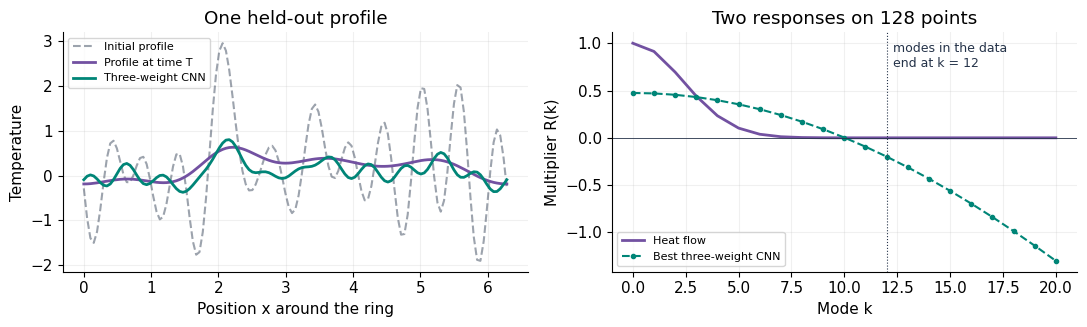

CNN weights (w_-1, w_0, w_1): [ 2.   -3.52  2.  ]
Held-out relative L2: 0.631


In [13]:
N, K_MAX, NU_T = 128, 12, 0.091
N_TRAIN_PAIRS, N_TEST_PAIRS = 64, 32
retained_k = np.arange(K_MAX + 1)
heat_response = np.exp(-NU_T*retained_k**2)   # used only to make the data

rng = np.random.default_rng(17)
coefficients = 0.15*(rng.normal(size=(N_TRAIN_PAIRS + N_TEST_PAIRS, K_MAX + 1))
                     + 1j*rng.normal(size=(N_TRAIN_PAIRS + N_TEST_PAIRS, K_MAX + 1)))
coefficients[:, 0] = coefficients[:, 0].real

def profiles(a, n):
    # Profiles with Fourier coefficients a for modes 0..K_MAX, sampled at n points.
    if n // 2 <= K_MAX:
        raise ValueError('The grid must resolve all retained modes below Nyquist.')
    padded = np.zeros((len(a), n//2 + 1), dtype=complex)
    padded[:, :K_MAX + 1] = a
    return irfft(padded, n)

initial = profiles(coefficients, N)
final = profiles(coefficients*heat_response, N)
train_u, test_u = initial[:N_TRAIN_PAIRS], initial[N_TRAIN_PAIRS:]
train_y, test_y = final[:N_TRAIN_PAIRS], final[N_TRAIN_PAIRS:]

cnn3 = fit_filter(train_u, train_y, 3)
cnn3_predictions = convolve(test_u, cnn3)

xx = grid(N)
k_plot = np.arange(21)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].plot(*close_periodic(xx, test_u[0]), '--', color=INK, alpha=0.45, label='Initial profile')
axes[0].plot(*close_periodic(xx, test_y[0]), color=EXACT, lw=2, label='Profile at time T')
axes[0].plot(*close_periodic(xx, cnn3_predictions[0]), color=FIELD, lw=2, label='Three-weight CNN')
axes[0].set(xlabel='Position x around the ring', ylabel='Temperature', title='One held-out profile')
axes[0].legend(fontsize=8)
axes[1].plot(k_plot, np.exp(-NU_T*k_plot**2), color=EXACT, lw=2, label='Heat flow')
axes[1].plot(k_plot, response(cnn3, k_plot, N).real, 'o--', color=FIELD, ms=3,
             label='Best three-weight CNN')
axes[1].axhline(0, color=INK, lw=0.6)
axes[1].axvline(K_MAX, color=INK, lw=0.8, ls=':')
axes[1].text(K_MAX + 0.3, 0.75, 'modes in the data\nend at k = 12', fontsize=9, color=INK)
axes[1].set(xlabel='Mode k', ylabel='Multiplier R(k)', title='Two responses on 128 points')
axes[1].legend(fontsize=8, loc='lower left')
fig.tight_layout()
plt.show()
print(f'CNN weights (w_-1, w_0, w_1): {np.round(cnn3, 2)}')
print(f'Held-out relative L2: {mean_relative_error(cnn3_predictions, test_y):.3f}')

The best three weights are approximately $(2.00,-3.52,2.00)$, yet the held-out relative error is about $0.63$—a poor approximation to heat flow.

Why? The CNN response is constrained to one cosine curve,

$$R_{\rm CNN}(k)\approx -3.52+4\cos\left(\frac{2\pi k}{128}\right).$$

It gives about $0.47$ at $k=1$ and $0.24$ at $k=7$, whereas heat flow requires about $0.91$ and $0.012$. The curve cannot remain near one for broad waves and fall rapidly toward zero for fine waves in exactly the way the heat equation demands.

Least squares has already found the best three-weight filter for these training pairs. More optimizer steps would not overcome this **restriction in the form of the response**. Perhaps the problem is simply that the spatial filter is too narrow.


## 6. How wide does a spatial filter need to be?

The inverse Fourier transform of the exact heat response $R_{\rm heat}(k)$ gives the **heat kernel**: the spatial weights that reproduce heat flow by convolution. On a periodic ring this is a wrapped Gaussian, with characteristic physical width

$$\sigma=\sqrt{2\nu T}\approx 0.43.$$

On our 128-point grid, that corresponds to about **8.7 grid spacings**. A three-weight CNN reaches only one point to either side, far less than that. It simply cannot gather information from enough of the ring in a single layer.

The next figure compares the heat kernel with the reach of short and wide CNN filters. Then the table fits filters of 3, 9, 17, and 25 weights to the **same training data**.


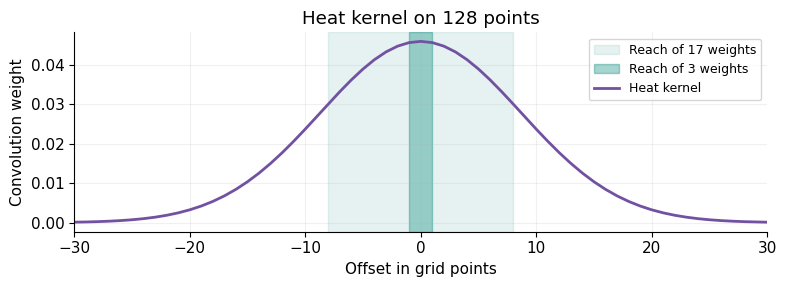

| CNN weights | Reach in grid points | Held-out relative L2 |
|---|---|---|
| 3 | 1 | 0.63 |
| 9 | 4 | 0.098 |
| 17 | 8 | 0.0035 |
| 25 | 12 | 0.00066 |

In [14]:
heat_kernel = np.fft.irfft(np.exp(-NU_T*np.arange(N//2 + 1)**2), n=N)
offset = np.arange(N) - N//2

fig, ax = plt.subplots(figsize=(8, 3))
ax.axvspan(-8, 8, color=FIELD, alpha=0.10, label='Reach of 17 weights')
ax.axvspan(-1, 1, color=FIELD, alpha=0.35, label='Reach of 3 weights')
ax.plot(offset, np.fft.fftshift(heat_kernel), color=EXACT, lw=2, label='Heat kernel')
ax.set(xlabel='Offset in grid points', ylabel='Convolution weight', xlim=(-30, 30),
       title='Heat kernel on 128 points')
ax.legend(fontsize=9)
fig.tight_layout()
plt.show()

rows = [(width, mean_relative_error(convolve(test_u, fit_filter(train_u, train_y, width)), test_y))
        for width in [3, 9, 17, 25]]
table = '| CNN weights | Reach in grid points | Held-out relative L2 |\n|---|---|---|\n'
table += '\n'.join(f'| {width} | {width//2} | {error:.2g} |' for width, error in rows)
display(Markdown(table))
cnn17 = fit_filter(train_u, train_y, 17)

Making the CNN wider works. A 17-weight filter reaches eight grid points to either side—nearly one standard deviation of the heat kernel—and reduces the held-out error to about $0.0035$.

But there is a catch: **physical distance and number of grid points are not the same thing**. The heat kernel's physical width is fixed by $\nu T$. On 128 points its standard deviation spans about 8.7 grid intervals; on 256 points it spans about 17.4. A fixed 17-weight CNN covers only half as much *physical distance* on the finer grid.

This suggests a different parameterization. Instead of counting how many neighboring grid points a kernel reaches, could we describe its action using **waves that mean the same thing on any grid**?


## 7. Learn the Fourier response directly

Here is the central FNO idea in its simplest form.

A CNN learns spatial weights $w_r$ and those weights *imply* a response $R(k)$. **What if we make $R(k)$ the parameters instead?** We learn one multiplier for each retained Fourier mode $k=0,1,\ldots,12$.

The distinction matters: $k=3$ always means **three periods around the physical ring**, whether we sample that ring with 128, 256, or 512 points. We are parameterizing the response by physical wavelength, not by a fixed number of neighboring pixels.

For heat flow, each training pair supplies a very direct relationship:

$$b_k=R(k)a_k,$$

where $a_k$ is the input Fourier coefficient and $b_k$ is the output coefficient. If we plot $b_k$ against $a_k$ across many examples, the points should lie on a line whose slope is the multiplier. The next cell shows this for the imaginary parts of modes 1, 3, and 7.


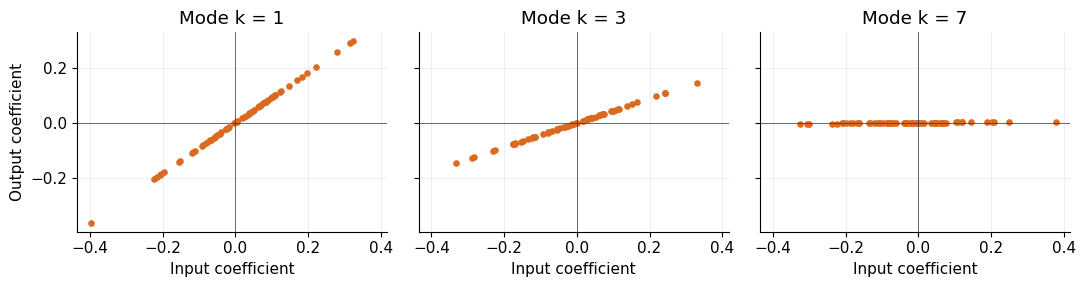

In [15]:
train_a, train_b = rfft(train_u), rfft(train_y)
fig, axes = plt.subplots(1, 3, figsize=(11, 3), sharex=True, sharey=True)
for ax, mode in zip(axes, [1, 3, 7]):
    ax.scatter(train_a[:, mode].imag, train_b[:, mode].imag, s=14, color=LEARNED)
    ax.set(xlabel='Input coefficient', title=f'Mode k = {mode}')
    ax.axhline(0, color=INK, lw=0.5)
    ax.axvline(0, color=INK, lw=0.5)
axes[0].set_ylabel('Output coefficient')
fig.tight_layout()
plt.show()

The slopes become smaller as the frequency increases: heat has damped the fine waves more strongly.

We can learn each complex Fourier multiplier by least squares:

$$
\boxed{R_{\rm learned}(k)=
\frac{\sum_j\overline{a_k^{(j)}}\,b_k^{(j)}}
{\sum_j\lvert a_k^{(j)}\rvert^2}.}
$$

Here, $j$ indexes training examples. The numerator measures how input and output coefficients correspond; the denominator measures how much of that mode the training data contain. If a mode never appears in the input, the denominator is zero: **there is no information from which to learn its response**.

This closed-form fit works because our demonstration is a *single linear Fourier layer*. A full FNO learns matrices that mix feature channels at each frequency, and composes them with pointwise and nonlinear operations. Its parameters are normally trained by gradient descent.

The next cell performs the three essential operations of a Fourier layer: **FFT $\rightarrow$ multiply the retained modes $\rightarrow$ inverse FFT**.


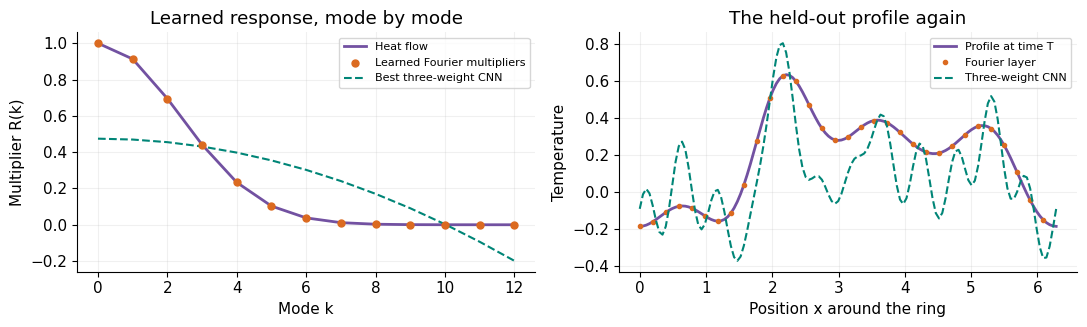

Fourier layer held-out relative L2: 2.23e-16


In [16]:
a = train_a[:, :K_MAX + 1]
b = train_b[:, :K_MAX + 1]
mode_energy = np.sum(np.abs(a)**2, axis=0)
assert np.all(mode_energy > 0)
learned_response = np.sum(a.conj()*b, axis=0) / mode_energy

def fourier_layer(u):
    # FFT, multiply modes 0..K_MAX by the learned response, inverse FFT.
    coefficients = rfft(u)
    out = np.zeros_like(coefficients)
    out[..., :K_MAX + 1] = learned_response*coefficients[..., :K_MAX + 1]
    return irfft(out, u.shape[-1])

fourier_predictions = fourier_layer(test_u)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].plot(retained_k, heat_response, color=EXACT, lw=2, label='Heat flow')
axes[0].scatter(retained_k, learned_response.real, color=LEARNED, s=25, zorder=3,
                label='Learned Fourier multipliers')
axes[0].plot(retained_k, response(cnn3, retained_k, N).real, '--', color=FIELD,
             label='Best three-weight CNN')
axes[0].set(xlabel='Mode k', ylabel='Multiplier R(k)', title='Learned response, mode by mode')
axes[0].legend(fontsize=8)
axes[1].plot(*close_periodic(xx, test_y[0]), color=EXACT, lw=2, label='Profile at time T')
axes[1].plot(xx[::4], fourier_predictions[0, ::4], 'o', color=LEARNED, ms=3, label='Fourier layer')
axes[1].plot(*close_periodic(xx, cnn3_predictions[0]), '--', color=FIELD, label='Three-weight CNN')
axes[1].set(xlabel='Position x around the ring', ylabel='Temperature', title='The held-out profile again')
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()
print(f'Fourier layer held-out relative L2: {mean_relative_error(fourier_predictions, test_y):.2e}')
assert np.allclose(learned_response, heat_response, atol=1e-13)

The result is nearly exact. The 13 learned multipliers agree with $e^{-\nu k^2T}$, and the held-out relative error is about $2.2\times10^{-16}$—essentially floating-point rounding. That is possible here because the data are noiseless, the underlying map is linear, and all test profiles contain only modes 0 through 12.

Now ask what those 13 spectral weights mean in **physical space**. Set the higher-frequency multipliers to zero and take an inverse FFT. We obtain a spatial convolution kernel spread over many grid points.

This is the surprising connection:

- A short CNN filter has a few local spatial weights, which determine its full frequency response.
- A Fourier layer has learned frequency weights, which determine a generally **wide, global spatial kernel**.

The next plot compares the spatial kernel implied by the learned Fourier multipliers with the exact heat kernel. This is the global convolution viewpoint described in [Li's introduction to FNO](https://zongyi-li.github.io/blog/2020/fourier-pde/).


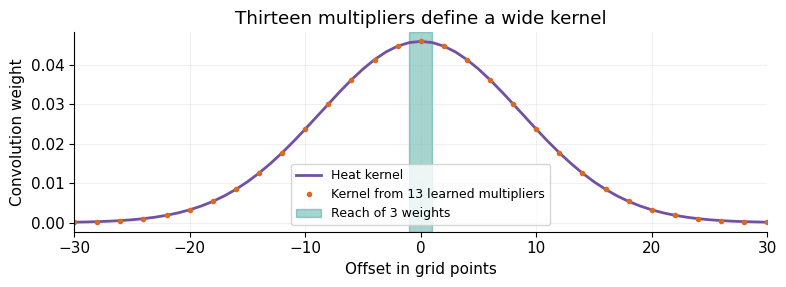

In [17]:
learned_full_response = np.zeros(N//2 + 1, dtype=complex)
learned_full_response[:K_MAX + 1] = learned_response
learned_kernel = np.fft.irfft(learned_full_response, n=N)
assert np.allclose(irfft(np.fft.rfft(learned_kernel)*rfft(test_u), N), fourier_predictions, atol=1e-13)

fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(offset, np.fft.fftshift(heat_kernel), color=EXACT, lw=2, label='Heat kernel')
ax.plot(offset[::2], np.fft.fftshift(learned_kernel)[::2], 'o', color=LEARNED, ms=3,
        label='Kernel from 13 learned multipliers')
ax.axvspan(-1, 1, color=FIELD, alpha=0.35, label='Reach of 3 weights')
ax.set(xlabel='Offset in grid points', ylabel='Convolution weight', xlim=(-30, 30),
       title='Thirteen multipliers define a wide kernel')
ax.legend(fontsize=9)
fig.tight_layout()
plt.show()

### Spatial weights and Fourier multipliers

**For heat flow, both ultimately do $a_k\mapsto R(k)a_k$, exactly as Section 4 showed. The difference is how they learn $R(k)$.**

Imagine the initial temperature contains three waves:

$$
u(x,0)=\sin x+\sin 3x+\sin 7x.
$$

After heat spreads for the time used in the notebook,

$$
u(x,T)\approx
0.91\sin x+0.44\sin 3x+0.012\sin 7x.
$$

The broad temperature variation mostly survives; the fine ripples almost disappear.

**The CNN learns how much neighboring temperatures contribute.**

A three-point CNN predicts each final temperature using

$$
u_j(T)\approx
w_{-1}u_{j+1}(0)+w_0u_j(0)+w_1u_{j-1}(0).
$$

Training adjusts those **three spatial weights**.

As Section 3 showed, when we feed it one wave, the shifted copies factor into $R(k)e^{ikx}$. For symmetric weights,

$$
R_{\mathrm{CNN}}(k)=w_0+2w_1\cos(kh).
$$

Here is the restriction: **the same spatial weights must produce the right multiplier for every wave.**

We want $R(1)=0.91$, $R(3)=0.44$, $R(7)=0.012$, and the correct values for all the other modes. A three-point filter cannot independently set those values. It finds a compromise.

Widening the CNN gives it more spatial weights, so it can shape its frequency response more accurately. Physically, it also lets each prediction gather temperatures from farther away.

**The Fourier layer learns how much each wave contributes.**

It first uses the FFT to find the waves present in the initial temperature. Then training adjusts the multipliers directly:

| Mode | Learned multiplier |
|---|---:|
| $k=1$ | $R(1)=0.91$ |
| $k=3$ | $R(3)=0.44$ |
| $k=7$ | $R(7)=0.012$ |

Each retained mode has its own parameter. The inverse FFT combines the modified waves into the final temperature profile.

**So why does Fourier work so well here?** Heat flow acts independently on each Fourier wave. Learning one multiplier per wave matches the structure of the physical solution exactly.

The factoring of Section 3 applies to both:

$$
\boxed{
\begin{aligned}
\text{CNN:}\quad &\text{learn spatial weights}\;\longrightarrow\;R(k),\\
\text{Fourier:}\quad &\text{learn }R(k)\text{ directly}.
\end{aligned}
}
$$

A sufficiently wide or deep CNN can also learn heat flow. The notebook shows why **one narrow CNN layer** struggles, while one Fourier layer handles this particular linear problem easily.

Do the waves stay fixed while training learns how strongly each one contributes?

**Yes. The waves stay fixed, and training learns how strongly each input wave contributes to the solution.**

For the heat example:

$$
\underbrace{u(x,0)=\sum_k a_k\,e^{ikx}}_{\text{initial temperature}}
\quad\longrightarrow\quad
\underbrace{u(x,T)=\sum_k R(k)a_k\,e^{ikx}}_{\text{final temperature}}.
$$

There are three separate things:

| Quantity | What happens to it? |
|---|---|
| Waves $e^{ikx}$ | Fixed sine and cosine patterns |
| Input coefficients $a_k$ | Computed by FFT; change with each input |
| Multipliers $R(k)$ | Learned during training; reused for new inputs |

For example, training learns $R(3)=0.44$. Then:

- An input containing wave 3 with amplitude **1** produces amplitude **0.44**.
- An input containing wave 3 with amplitude **2** produces amplitude **0.88**.

So **the learned quantity is the scaling rule $R(k)$**. The amount of that wave in a particular solution is $R(k)a_k$, which depends on the input.

For the question of which waves to keep: we usually choose a maximum mode $k_{\max}$ and retain modes $0,\ldots,k_{\max}$. The notebook uses $k_{\max}=12$. On a ring, mode $k$ always means $k$ complete cycles around the ring—the wave shapes themselves are prescribed.

## 8. What happens on a finer grid?

We have trained both models on **128 grid points**. Now evaluate them on 256 and 512 points without retraining.

Why might they behave differently? A fixed-width CNN sees neighbors a fixed number of *pixels* away. As the grid becomes finer, those pixels get physically closer together. Its response depends on

$$\theta_k=\frac{2\pi k}{N}.$$

Doubling $N$ halves $\theta_k$ for the same physical mode $k$. So the CNN's response to mode $k$ on 256 points is the same cosine-based response that it assigned to approximately mode $k/2$ on 128 points. For a filter approximating heat flow, this means it tends to behave like **heat acting for a shorter time**, approximately $T/4$ on 256 points and $T/16$ on 512 points. The prediction is approximate for a fitted, finite-width kernel.

A Fourier layer instead stores a multiplier **indexed directly by mode $k$**. The multiplier for three cycles around the ring is still the multiplier for three cycles, no matter how many sample points resolve those cycles.

The next cell evaluates the learned Fourier layer and the 17-weight CNN on the same 32 held-out profiles at three resolutions. It compares each output with heat flow at time $T$, and also checks the CNN against the predicted shorter diffusion time.


| Points | Fourier layer vs time T | 17-weight CNN vs time T | 17-weight CNN vs time T/s | s |
|---|---|---|---|---|
| 128 | 2.2e-16 | 0.0035 | 0.0035 | 1 |
| 256 | 2.1e-16 | 0.78 | 0.0028 | 4 |
| 512 | 2.2e-16 | 1.7 | 0.0021 | 16 |

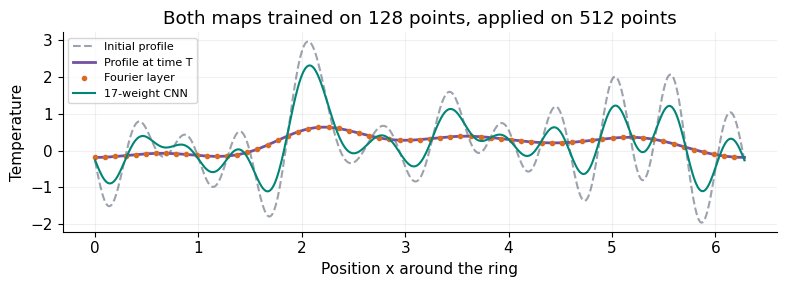

In [18]:
test_coefficients = coefficients[N_TRAIN_PAIRS:]
rows = []
for n in [128, 256, 512]:
    inputs = profiles(test_coefficients, n)
    target_T = profiles(test_coefficients*heat_response, n)
    s = (n // N)**2
    target_short = profiles(test_coefficients*np.exp(-NU_T*retained_k**2/s), n)
    cnn_out = convolve(inputs, cnn17)
    rows.append((n, s, mean_relative_error(fourier_layer(inputs), target_T),
                 mean_relative_error(cnn_out, target_T), mean_relative_error(cnn_out, target_short)))
    if n == 512:
        fine = (grid(n), inputs[0], target_T[0], fourier_layer(inputs)[0], cnn_out[0])

table = '| Points | Fourier layer vs time T | 17-weight CNN vs time T | 17-weight CNN vs time T/s | s |\n'
table += '|---|---|---|---|---|\n'
table += '\n'.join(f'| {n} | {f:.1e} | {c:.2g} | {c_short:.2g} | {s} |' for n, s, f, c, c_short in rows)
display(Markdown(table))

fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(*close_periodic(fine[0], fine[1]), '--', color=INK, alpha=0.45, label='Initial profile')
ax.plot(*close_periodic(fine[0], fine[2]), color=EXACT, lw=2, label='Profile at time T')
ax.plot(fine[0][::8], fine[3][::8], 'o', color=LEARNED, ms=3, label='Fourier layer')
ax.plot(*close_periodic(fine[0], fine[4]), color=FIELD, lw=1.5, label='17-weight CNN')
ax.set(xlabel='Position x around the ring', ylabel='Temperature',
       title='Both maps trained on 128 points, applied on 512 points')
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()
assert max(row[2] for row in rows) < 1e-12

The results support that prediction. The 17-weight CNN is accurate at its training resolution, but its error relative to the desired time-$T$ solution rises to about $0.78$ on 256 points and $1.7$ on 512 points. Against the **shorter** heat-flow times $T/4$ and $T/16$, its errors are only about $0.0028$ and $0.0021$.

The Fourier layer remains at rounding-error accuracy on all three grids. **It learned a response associated with each physical Fourier mode, not a fixed distance measured in pixels.**

There is an important limit to this result. All our signals contain only modes 0 through 12, and every test grid resolves those modes. A finer grid does *not* magically recover frequencies absent from the training data. Nor does a single Fourier multiplier solve an arbitrary nonlinear or position-dependent PDE.

**Where does the full FNO come in?** In this notebook, the heat map is a linear convolution, so one multiplier per mode is enough. For nonlinear problems, FNO alternates spectral convolutions with pointwise channel mixing and nonlinear activations. Those nonlinear steps let frequencies interact across layers. Section 6 of [the heat-flow lesson](fno-intuition.ipynb) builds that full layer and examines what happens when new frequencies are generated.


## Try it yourself

1. **Stack two blurs.** Using the result from Section 3, predict the frequency response of two successive blur filters. Verify the prediction with an FFT.
2. **Understand an edge detector.** The filter on slide 12 has rows $(1,1,1)$, $(0,0,0)$, and $(-1,-1,-1)$. Derive $R(k_1,k_2)$. Which frequencies disappear? What happens to a constant image?
3. **Inspect the wide CNN.** Print the 17 weights learned in Section 6. Why do they have those values, given the modes present in the training data? Test the same filter on 64 points.
4. **Explore aliasing.** Sample $\sin(9x)$ at 24 points and square it. The true square contains mode 18. Which lower frequency has the same samples? Repeat on 96 points before keeping only modes through 10.

### What to remember

A convolution computes a sum of shifted copies of a field. For a Fourier wave, every shift is equivalent to multiplication by a phase factor. **That is why convolution becomes multiplication in Fourier space.** A CNN chooses a small set of spatial weights and inherits their frequency response; a Fourier layer learns selected frequency responses directly. Both represent convolution, but they organize their parameters differently.

The convolution, stride, and pooling animations and the image filters come from slides 14–23 of the Module 6 CNN deck. [Li's FNO explanation](https://zongyi-li.github.io/blog/2020/fourier-pde/) discusses global convolution. [Trautner, Lanthaler, and Stuart](https://arxiv.org/abs/2405.02221) analyze discretization error, resolution transfer, and aliasing.
